# Packing $n$ unit squares into the smallest square

### The map: what is proved, what is open, and how to actually build a packing

This notebook answers one question first — **what is the mathematical
minimum?** — and then builds the machinery to hunt for it.

Everything runs on plain NumPy. Nothing here needs a GPU, a solver, or an
internet connection.

**Contents**

| § | What it covers |
|---|---|
| 0 | The answer, in one table |
| 1 | The problem, stated precisely |
| 2 | Why $\sqrt{n}$ is the floor (area bound) |
| 3 | When the floor is **reached** — and why that pins down exactly 31 puzzles |
| 4 | What is actually known for $n=1\ldots20$ (and what is still open) |
| 5 | Testing legality: two independent overlap tests |
| 6 | The trivial baseline, and where the leaderboard points live |
| 7 | A search engine (shrink-wrap) and what it can and cannot do |
| 8 | Strategy for the competition |
| 9 | Writing and self-scoring a submission |

## 0. The answer

The competition score for one puzzle is

$$\text{score}(n) \;=\; \frac{L(n)}{\sqrt{n}} \;-\; 1,$$

where $L(n)$ is the side of the tightest axis-aligned square containing your
$n$ unit squares.

**The floor is $0$, and it is reached if and only if $n$ is a perfect square.**

So:

| $n$ | Best possible $L$ | Best possible score | How many such puzzles for $n\le 1000$ |
|---|---|---|---|
| $k^2$ | exactly $k=\sqrt n$ | exactly $0$ | **31** |
| everything else | strictly $>\sqrt n$ | strictly $>0$, **unknown** | 969 |

People posting `1.000000000000000` (or a score of `0.000000000000000`) are
showing you ratio-1 solutions — those are the perfect squares, where the $k
\times k$ grid **is** the optimum and there is nothing left to find. If you ever
see a ratio of $1.0000000000$ for a non-square $n$, something is wrong: either
the squares genuinely overlap, or the numbers are not being read the way you
think they are — because by §3 that ratio is geometrically impossible.

What nobody can tell you is the *other* number: the true minimum of
$\sum_{n=1}^{1000}\text{score}(n)$. Roughly a hundred of the 1000 puzzles have
a proved optimum — most of them just because they fall into one of the three
solved families in §4 — and the other nine hundred are open. That is exactly
why this is a competition.

## 1. The problem, stated precisely

A packing is a list of $n$ triples $(x_i, y_i, \theta_i)$:

* $(x_i,y_i)$ is the **centre** of square $i$,
* $\theta_i$ is its **rotation in radians**,
* every square has side $1$, so square $i$ is the set
  $\;c_i + R(\theta_i)\,[-\tfrac12,\tfrac12]^2$.

Two structural facts make this problem nicer than it looks:

**The container is derived, not chosen.** You never submit $L$. The grader
builds the tightest axis-aligned square around your squares, so
$$L \;=\; \max\bigl(\underbrace{\max_i x - \min_i x}_{w},\;
\underbrace{\max_i y - \min_i y}_{h}\bigr).$$
There are therefore **no boundary constraints at all** — only non-overlap
matters, and $L$ is whatever falls out. It also means $L$ is a *minimax*
objective: the optimum always has $w \approx h$, because you can trade width for
height by rotating.

**Touching is legal.** The rule is that the *interior* intersection must be
zero, so squares may share edges and corners. This is why the perfect squares
score exactly $0$ rather than "almost $0$".

### The toolkit

The cells below are the whole toolkit, in the order you need it:

1. geometry — corners, container side, score
2. the separating-axis test — an exact pairwise non-overlap predicate
3. constructions — the trivial grid
4. a shrink-wrap optimiser
5. simulated annealing
6. submission I/O

Read the docstrings: they carry the reasoning, and the comments explain the
non-obvious algebra (especially the SAT projection formula, which is the one
piece of bit-twiddling worth understanding).

#### Imports and conventions

In [1]:
import numpy as np

# A pair is "overlapping" if its interiors share area. Touching is legal
# (the statement of the problem is about interiors), but floating point means
# we always finish with a small positive gap, see `polish`.
GAP = 1e-7
# Penetration below this is treated as numerical dust, not a violation.
TOL = 1e-9

#### Geometry: corners, container side, score

In [2]:
def pairs(n: int) -> tuple[np.ndarray, np.ndarray]:
    """All index pairs i < j."""
    return np.triu_indices(n, 1)


def half_extent(th: np.ndarray) -> np.ndarray:
    """Half-width of a unit square rotated by th, along the x axis.

    Same value along y: a unit square rotated by th has axis-aligned
    bounding box side (|cos th| + |sin th|)."""
    return 0.5 * (np.abs(np.cos(th)) + np.abs(np.sin(th)))


def corners(xy: np.ndarray, th: np.ndarray) -> np.ndarray:
    """(n, 4, 2) array of the four corners of every square."""
    c, s = np.cos(th), np.sin(th)
    lx = np.array([-0.5, 0.5, 0.5, -0.5])
    ly = np.array([-0.5, -0.5, 0.5, 0.5])
    x = xy[:, 0:1] + c[:, None] * lx - s[:, None] * ly
    y = xy[:, 1:2] + s[:, None] * lx + c[:, None] * ly
    return np.stack([x, y], axis=-1)


def container_side(xy: np.ndarray, th: np.ndarray) -> float:
    """L, the side of the tightest axis-aligned square around the union."""
    p = corners(xy, th)
    x, y = p[..., 0], p[..., 1]
    return float(max(x.max() - x.min(), y.max() - y.min()))


def score(L: float, n: int) -> float:
    """Competition metric for one puzzle."""
    return L / np.sqrt(n) - 1.0


def grid_side(n: int) -> int:
    """Side of the trivial grid packing: ceil(sqrt n)."""
    return int(np.ceil(np.sqrt(n) - 1e-12))

#### The separating-axis test (exact non-overlap)

In [3]:
def sat_depths(xy: np.ndarray, th: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Per-pair penetration depth along the four SAT axes.

    Returns (depth, axes, delta) with shapes (P, 4), (P, 4, 2), (P, 2).
    depth[p, k] > 0  <=>  the projections overlap on axis k.
    For convex polygons, "interiors intersect" <=> every axis overlaps, so the
    penetration depth of the pair is depth.min(axis=1).
    """
    n = len(xy)
    iu, ju = pairs(n)
    c, s = np.cos(th), np.sin(th)
    U = np.stack([c, s], axis=-1)          # square edge directions
    V = np.stack([-s, c], axis=-1)
    axes = np.stack([U[iu], V[iu], U[ju], V[ju]], axis=1)   # (P, 4, 2), unit
    delta = xy[ju] - xy[iu]
    proj = np.abs(np.einsum("pkd,pd->pk", axes, delta))
    r = 0.5 * (
        np.abs(np.einsum("pkd,pd->pk", axes, U[iu]))
        + np.abs(np.einsum("pkd,pd->pk", axes, V[iu]))
        + np.abs(np.einsum("pkd,pd->pk", axes, U[ju]))
        + np.abs(np.einsum("pkd,pd->pk", axes, V[ju]))
    )
    return r - proj, axes, delta


def max_penetration(xy: np.ndarray, th: np.ndarray) -> float:
    """Largest pairwise penetration depth. <= 0 means pairwise disjoint."""
    n = len(xy)
    if n < 2:
        return 0.0
    depth, _, _ = sat_depths(xy, th)
    return float(depth.min(axis=1).max())


def is_valid(xy: np.ndarray, th: np.ndarray) -> tuple[bool, dict]:
    """Independent validation, mirroring what the grader must check."""
    n = len(xy)
    pen = max_penetration(xy, th)
    L = container_side(xy, th)
    finite = bool(np.isfinite(xy).all() and np.isfinite(th).all())
    ok = finite and pen <= TOL and L > 0
    return ok, {"max_penetration": pen, "L": L, "finite": finite, "n": n}

#### Constructions: the trivial grid

In [4]:
def grid(n: int) -> tuple[np.ndarray, np.ndarray]:
    """The trivial baseline: n axis-aligned squares in a k x k grid."""
    k = grid_side(n)
    idx = np.arange(n)
    xy = np.stack([idx % k + 0.5, idx // k + 0.5], axis=-1).astype(float)
    return xy, np.zeros(n)


def centered(xy: np.ndarray, th: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Translate so the bounding box starts at the origin."""
    p = corners(xy, th)
    lo = p.reshape(-1, 2).min(axis=0)
    return xy - lo, th

#### Optimiser 1: shrink-wrap (physics repair inside a shrinking window)

In [5]:
def relax(
    xy: np.ndarray,
    th: np.ndarray,
    L: float,
    iters: int,
    rng: np.random.Generator,
    step: float = 0.55,
    sigma: float = 0.0,
    sigma_decay: float = 0.995,
) -> tuple[np.ndarray, np.ndarray, float]:
    """Push the packing into the window [0, L]^2 and kill overlaps.

    Pure physics: each overlapping pair is separated along its minimum
    translation vector; squares are projected back into the container box.
    `sigma` adds rotational noise to squares that are still in conflict, which
    is what lets the search discover rotated configurations.
    Returns the configuration and the residual penetration.
    """
    xy = xy.copy()
    th = th.copy()
    n = len(xy)
    if n > 1:
        iu, ju = pairs(n)

    for _ in range(iters):
        h = half_extent(th)
        hi = np.maximum(L - h, h)
        xy[:, 0] = np.clip(xy[:, 0], h, hi)
        xy[:, 1] = np.clip(xy[:, 1], h, hi)
        if n < 2:
            return xy, th, 0.0

        depth, axes, delta = sat_depths(xy, th)
        pen = depth.min(axis=1)
        if pen.max() <= 0.0:
            return xy, th, 0.0

        act = pen > 0.0
        k = np.argmin(depth, axis=1)
        # unit MTV axis and the sign that pushes j away from i
        a = axes[np.arange(len(k)), k]
        sgn = np.sign(np.einsum("pd,pd->p", a, delta))
        sgn[sgn == 0.0] = 1.0
        vec = (a * sgn[:, None]) * (0.5 * step * pen)[:, None] * act[:, None]

        dx = np.zeros((n, 2))
        cnt = np.zeros((n, 1))
        np.add.at(dx, iu, -vec)
        np.add.at(dx, ju, +vec)
        np.add.at(cnt, iu, act[:, None])
        np.add.at(cnt, ju, act[:, None])
        xy += dx / np.maximum(cnt, 1.0)

        if sigma > 0.0:
            hot = np.zeros(n, dtype=bool)
            hot[iu[act]] = True
            hot[ju[act]] = True
            th[hot] += rng.normal(0.0, sigma, size=int(hot.sum()))
            sigma *= sigma_decay

    if n < 2:
        return xy, th, 0.0
    depth, _, _ = sat_depths(xy, th)
    return xy, th, float(depth.min(axis=1).max())


def _fit_into(xy, th, window, rng, iters, sigma, step=0.9):
    """Re-centre and squash a packing into a smaller window, then repair it.

    Returns candidate (xy, th, L, penetration)."""
    xy, th = centered(xy, th)
    cur = container_side(xy, th)
    scale = min(window / max(cur, 1e-12), 1.0)
    xy = xy * scale
    xy, th, pen = relax(xy, th, window, iters, rng, step=step, sigma=sigma)
    xy, th = centered(xy, th)
    return xy, th, container_side(xy, th), pen


def shrink(
    n: int,
    start: tuple[np.ndarray, np.ndarray] | None = None,
    goal: float | None = None,
    rounds: int = 70,
    iters: int = 400,
    eta: float = 0.004,
    sigma: float = 0.08,
    step: float = 0.9,
    kicks: int = 0,
    seed: int = 0,
    log=None,
) -> dict:
    """Shrink-wrap by bisection on the container side.

    Maintains a feasible side `hi` and an infeasible side `lo`; each round
    tries the midpoint (or at least an `eta` improvement), repairs overlaps
    inside that window, and moves whichever bracket end the result lands on.
    `goal` is a hard floor on L (default: the area bound sqrt(n)).
    """
    rng = np.random.default_rng(seed)
    if start is None:
        xy, th = centered(*grid(n))
    else:
        xy, th = centered(start[0].copy(), start[1].copy())
    if goal is None:
        goal = float(np.sqrt(n))
    goal = max(goal, float(np.sqrt(n)))

    hi = container_side(xy, th)
    best = {"L": hi, "xy": xy.copy(), "th": th.copy()}
    step_frac = eta
    fails = 0

    for r in range(rounds):
        window = max(hi * (1.0 - step_frac), goal)
        if window >= hi * (1.0 - 1e-12):
            break
        xy1, th1, L1, pen = _fit_into(
            best["xy"], best["th"], window, rng, iters,
            sigma * (1.0 - 0.6 * r / max(rounds, 1)), step)
        if pen <= TOL and L1 <= window * (1.0 + 1e-12):
            hi = min(L1, window)
            best = {"L": hi, "xy": xy1.copy(), "th": th1.copy()}
            fails = 0
            step_frac = min(eta, step_frac * 1.5)
            if log:
                log(f"  n={n:4d} r{r:3d}  L={hi:.10f}  score={score(hi, n):.6f}")
        else:
            fails += 1
            step_frac *= 0.5
            if fails >= 4 and kicks > 0:
                # basin hop: shake the best configuration and retry the window
                th0 = best["th"] + rng.normal(0.0, 0.3, size=n)
                xy0, th0_, L0, pen0 = _fit_into(best["xy"], th0, window, rng, iters,
                                               sigma * 2.5, step)
                if pen0 <= TOL and L0 < hi:
                    hi, best = L0, {"L": L0, "xy": xy0.copy(), "th": th0_.copy()}
                    if log:
                        log(f"  n={n:4d} kick  L={hi:.10f}  score={score(hi, n):.6f}")
                fails = 0
                step_frac = eta
            if step_frac < 1e-7:
                step_frac = eta  # restart the fine step after a kick

    return {"n": n, "L": best["L"], "xy": best["xy"], "th": best["th"],
            "score": score(best["L"], n)}


def polish(xy: np.ndarray, th: np.ndarray, rng, iters: int = 300) -> tuple[np.ndarray, np.ndarray]:
    """Finish with a strictly positive gap so the grader sees no overlap.

    Inflates the squares by GAP and re-separates; the container grows by about
    2*GAP, which is far below the submission's rounding error.
    """
    n = len(xy)
    if n < 2:
        return xy, th
    iu, ju = pairs(n)
    xy = xy.copy()
    th = th.copy()
    for _ in range(iters):
        depth, axes, delta = sat_depths(xy, th)
        pen = depth.min(axis=1)
        bad = pen > -GAP
        if not bad.any():
            break
        k = np.argmin(depth, axis=1)
        a = axes[np.arange(len(k)), k]
        sgn = np.sign(np.einsum("pd,pd->p", a, delta))
        sgn[sgn == 0.0] = 1.0
        push = (pen + GAP).clip(min=0.0)
        vec = (a * sgn[:, None]) * (0.55 * push)[:, None] * bad[:, None]
        dx = np.zeros((n, 2))
        cnt = np.zeros((n, 1))
        np.add.at(dx, iu, -vec)
        np.add.at(dx, ju, +vec)
        np.add.at(cnt, iu, bad[:, None])
        np.add.at(cnt, ju, bad[:, None])
        xy += dx / np.maximum(cnt, 1.0)
    return xy, th

#### Optimiser 2: simulated annealing on a fixed window

In [6]:
def _pen_vs_all(xy, th, i):
    """Penetration depth of square i against every other square (n,)."""
    n = len(xy)
    c, s = np.cos(th), np.sin(th)
    U = np.stack([c, s], axis=-1)
    V = np.stack([-s, c], axis=-1)
    j = np.arange(n)
    A = np.stack([np.broadcast_to(U[i], (n, 2)), np.broadcast_to(V[i], (n, 2)),
                  U, V], axis=1)                     # (n, 4, 2)
    delta = xy - xy[i]
    proj = np.abs(np.einsum("pkd,pd->pk", A, delta))
    r = 0.5 * (np.abs(A @ U[i]) + np.abs(A @ V[i])
               + np.abs(np.einsum("pkd,pd->pk", A, U))
               + np.abs(np.einsum("pkd,pd->pk", A, V)))
    depth = (r - proj).min(axis=1)
    depth[i] = -np.inf
    return depth


def energy(xy, th, L, wall=4.0):
    """Penalty: squared penetration of every overlapping pair plus squared
    excursion of any square outside the window [0, L]^2. Zero <=> feasible."""
    n = len(xy)
    e = 0.0
    if n > 1:
        depth, _, _ = sat_depths(xy, th)
        pen = np.maximum(depth.min(axis=1), 0.0)
        e += float(np.sum(pen * pen))
    h = half_extent(th)
    vx = np.maximum(h - xy[:, 0], 0.0) + np.maximum(xy[:, 0] + h - L, 0.0)
    vy = np.maximum(h - xy[:, 1], 0.0) + np.maximum(xy[:, 1] + h - L, 0.0)
    e += wall * float(np.sum(vx * vx + vy * vy))
    return e


def sa_feasible(
    n: int,
    L: float,
    iters: int = 40000,
    T0: float = 4e-3,
    T1: float = 2e-6,
    move: float = 0.10,
    rot: float = 0.30,
    wall: float = 4.0,
    rng: np.random.Generator | None = None,
    init: tuple[np.ndarray, np.ndarray] | None = None,
):
    """Metropolis search for a zero-energy (overlap-free, inside) packing.

    Incremental energy: a move touches one square, so only that square's row of
    pairwise penalties and its wall term are recomputed.
    """
    rng = rng or np.random.default_rng(0)
    if init is None:
        xy = rng.random((n, 2)) * L
        th = rng.random(n) * np.pi
    else:
        xy, th = init[0].copy(), init[1].copy()
    xy = np.clip(xy, 0.0, L)

    cur = energy(xy, th, L, wall)
    best = (cur, xy.copy(), th.copy())
    logT = np.log(T0)
    dlog = (np.log(T1) - logT) / max(iters - 1, 1)

    for it in range(iters):
        T = np.exp(logT + dlog * it)
        i = int(rng.integers(n))
        ox, oy, oth = xy[i, 0], xy[i, 1], th[i]
        old_row = 0.0
        if n > 1:
            d_old = np.maximum(_pen_vs_all(xy, th, i), 0.0)
            old_row = float(np.sum(d_old * d_old))
        h_old = half_extent(th[i])
        vx = max(h_old - xy[i, 0], 0.0) + max(xy[i, 0] + h_old - L, 0.0)
        vy = max(h_old - xy[i, 1], 0.0) + max(xy[i, 1] + h_old - L, 0.0)
        old_wall = wall * (vx * vx + vy * vy)

        scale = move * L * (0.35 + 0.65 * T / T0)
        xy[i, 0] = ox + rng.normal(0.0, scale)
        xy[i, 1] = oy + rng.normal(0.0, scale)
        if rng.random() < 0.5:
            th[i] = oth + rng.normal(0.0, rot * (0.35 + 0.65 * T / T0))

        new_row = 0.0
        if n > 1:
            d_new = np.maximum(_pen_vs_all(xy, th, i), 0.0)
            new_row = float(np.sum(d_new * d_new))
        h_new = half_extent(th[i])
        vx = max(h_new - xy[i, 0], 0.0) + max(xy[i, 0] + h_new - L, 0.0)
        vy = max(h_new - xy[i, 1], 0.0) + max(xy[i, 1] + h_new - L, 0.0)
        new_wall = wall * (vx * vx + vy * vy)

        delta = (new_row + new_wall) - (old_row + old_wall)
        if delta <= 0.0 or rng.random() < np.exp(-delta / max(T, 1e-12)):
            cur += delta
            if cur < best[0] - 1e-15:
                best = (cur, xy.copy(), th.copy())
                if cur <= 1e-18:
                    break
        else:
            xy[i, 0], xy[i, 1], th[i] = ox, oy, oth

    return best[0], best[1], best[2]


def sa_descent(
    n: int,
    start: tuple[np.ndarray, np.ndarray] | None = None,
    goal: float | None = None,
    rounds: int = 40,
    iters: int = 30000,
    eta: float = 0.01,
    seed: int = 0,
    log=None,
) -> dict:
    """Descend the container side, asking SA each round whether it is feasible."""
    rng = np.random.default_rng(seed)
    if goal is None:
        goal = float(np.sqrt(n))
    goal = max(goal, float(np.sqrt(n)))

    if start is None:
        xy, th = centered(*grid(n))
        # start already inside its own window
        L = container_side(xy, th)
    else:
        xy, th = start[0].copy(), start[1].copy()
        L = container_side(xy, th)
        xy, th = centered(xy, th)
    best = {"L": L, "xy": xy.copy(), "th": th.copy()}

    for r in range(rounds):
        target = max(L * (1.0 - eta), goal)
        if target >= L * (1.0 - 1e-12):
            break
        # squash the incumbent into the candidate window, then anneal
        x0 = xy.copy() * min(target / max(container_side(xy, th), 1e-12), 1.0)
        e, x1, t1 = sa_feasible(n, target, iters=iters, rng=rng, init=(x0, th))
        x1, t1 = centered(x1, t1)
        if e <= 1e-14 and max_penetration(x1, t1) <= TOL:
            L = min(container_side(x1, t1), target)
            best = {"L": L, "xy": x1.copy(), "th": t1.copy()}
            xy, th = x1, t1
            if log:
                log(f"  n={n:4d} r{r:3d}  L={L:.10f}  score={score(L, n):.6f}")
        else:
            # infeasible: try once more from the incumbent with fresh noise
            e, x2, t2 = sa_feasible(n, target, iters=iters, rng=rng, init=(x0, th))
            x2, t2 = centered(x2, t2)
            if e <= 1e-14 and max_penetration(x2, t2) <= TOL:
                L = min(container_side(x2, t2), target)
                best = {"L": L, "xy": x2.copy(), "th": t2.copy()}
                xy, th = x2, t2
            else:
                eta *= 0.6
                if eta < 1e-5:
                    break

    return {"n": n, "L": best["L"], "xy": best["xy"], "th": best["th"],
            "score": score(best["L"], n)}

#### Submission I/O and self-scoring

In [7]:
def submission_rows(solutions: dict[int, tuple[np.ndarray, np.ndarray]]) -> list[tuple]:
    """(id, n, square_id, x, y, angle) rows in the required format."""
    rows = []
    sid = 0
    for n in sorted(solutions):
        xy, th = solutions[n]
        xy, th = centered(xy, th)
        for i in range(n):
            rows.append(
                (sid, n, i, float(xy[i, 0]), float(xy[i, 1]), float(th[i]))
            )
            sid += 1
    return rows


def write_submission(path: str, solutions: dict[int, tuple[np.ndarray, np.ndarray]]) -> None:
    """Write the CSV with plain decimal literals (repr is exact round-trip)."""
    rows = submission_rows(solutions)
    with open(path, "w", encoding="utf-8", newline="") as f:
        f.write("id,n,square_id,x,y,angle\n")
        for sid, n, i, x, y, t in rows:
            f.write(f"{sid},{n},{i},{x!r},{y!r},{t!r}\n")


def evaluate_submission(path: str, n_max: int = 1000) -> dict:
    """Re-read our own CSV and recompute the leaderboard sum exactly.

    This is the same arithmetic the grader performs: group by n, rebuild the
    packing, check non-overlap, compute L, charge the grid ceiling for any
    puzzle that is missing or invalid.
    """
    import csv

    by_n: dict[int, list[tuple]] = {}
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            n = int(row["n"])
            by_n.setdefault(n, []).append(
                (float(row["x"]), float(row["y"]), float(row["angle"]))
            )

    total = 0.0
    detail = []
    for n in range(1, n_max + 1):
        if n not in by_n or len(by_n[n]) != n:
            total += grid_side(n) / np.sqrt(n) - 1.0
            detail.append((n, grid_side(n), "grid (missing/partial)"))
            continue
        xy = np.array([(r[0], r[1]) for r in by_n[n]])
        th = np.array([r[2] for r in by_n[n]])
        ok, info = is_valid(xy, th)
        if ok:
            L = info["L"]
            total += L / np.sqrt(n) - 1.0
            detail.append((n, L, "packed"))
        else:
            total += grid_side(n) / np.sqrt(n) - 1.0
            detail.append((n, grid_side(n), f"invalid ({info['max_penetration']:.2e})"))
    return {"total": total, "detail": detail}

Sanity check — the grid must validate, and a deliberate overlap must not:

In [8]:
import numpy as np

xy, th = grid(6)
ok, info = is_valid(xy, th)
print("grid(6)          ->", ok, {k: round(v, 12) if isinstance(v, float) else v for k, v in info.items()})

xy_bad = np.array([[0.0, 0.0], [0.5, 0.5]])
th_bad = np.array([0.0, 0.3])
ok_bad, info_bad = is_valid(xy_bad, th_bad)
print("overlapping pair ->", ok_bad, f"penetration={info_bad['max_penetration']:.6f}")

grid(6)          -> True {'max_penetration': 0.0, 'L': 3.0, 'finite': True, 'n': 6}
overlapping pair -> False penetration=0.500000


## 2. Why $\sqrt{n}$ is the floor

This is the only bound the competition gives you, and it is worth deriving once
so you can see exactly how weak it is.

Each unit square has area $1$, so $n$ of them have total area $n$. They sit
inside a square of side $L$ with area $L^2$. Areas add (interiors are disjoint),
so

$$n \;\le\; L^2 \qquad\Longrightarrow\qquad L \;\ge\; \sqrt{n}
\qquad\Longrightarrow\qquad \text{score} \;\ge\; 0 .$$

Note what the inequality costs you: it counts *area only*. It knows nothing
about the fact that squares cannot be cut up, so as a function of $n$ it is
hopeless — it says the floor for $n=5$ is $2.236$, while the truth is
$2.707$. The gap between the two is where all the mathematics lives.

In [9]:
print(f"{'n':>4} {'sqrt(n) (area floor)':>21} {'grid L':>7} {'grid score':>11}")
print("-" * 46)
for n in [2, 3, 5, 6, 7, 10, 12, 17, 18, 20]:
    k = grid_side(n)
    print(f"{n:>4} {np.sqrt(n):>21.6f} {k:>7} {score(k, n):>11.6f}")

   n  sqrt(n) (area floor)  grid L  grid score
----------------------------------------------
   2              1.414214       2    0.414214
   3              1.732051       2    0.154701
   5              2.236068       3    0.341641
   6              2.449490       3    0.224745
   7              2.645751       3    0.133893
  10              3.162278       4    0.264911
  12              3.464102       4    0.154701
  17              4.123106       5    0.212678
  18              4.242641       5    0.178511
  20              4.472136       5    0.118034


## 3. When the floor is reached — and why that pins down exactly 31 puzzles

We can settle the $n=k^2$ question completely, and the argument is short enough
to fit in a paragraph. It is the reason the "1.0000…" scores on the leaderboard
are not suspicious.

**Claim.** A square can be tiled by $n$ congruent squares $\iff$ $n$ is a
perfect square.

**Proof.** ($\Leftarrow$) The $k\times k$ grid, $n=k^2$, obviously works.

($\Rightarrow$) Suppose the unit squares tile a square of side $L$. Each tile's
edges all lie in one of two perpendicular directions, $u$ and $u^\perp$; a
*square* has only four edge directions, so this is a property of $\theta_i$
alone — all congruent tiles share the same pair of directions, call it
$\{u,u^\perp\}$.

Now look at the bottom edge of the container. The container equals the union of
the tiles, so the bottom edge lies in the union's boundary, and every point of
it lies on some tile's boundary — necessarily along a tile *edge* (a tile
touching that line at a single vertex cannot cover a segment of it, and no tile
may poke through). That tile edge is horizontal, hence $u$ is horizontal. All
tiles are therefore **axis-aligned**.

A square of side $L$ tiled by axis-aligned unit squares: the bottom edge is a
union of complete unit edges, so $L$ is an integer $m$; the area is then
$m^2$, so $n = m^2$. $\blacksquare$

**Connecting the tiling to the competition.** Two more lines:

1. *The minimum is attained.* For fixed $n$ the set of legal configurations, after
   normalising translations, is closed and bounded (compact), and
   $L(\text{config})$ is continuous — so a minimiser exists. There is no
   "infimum never reached" pathology here; the optimum is a real configuration.
2. *If the optimum score were $0$*, then $L^\ast = \sqrt n$ and the container's area
   $L^{\ast2} = n$ equals the total area of the squares. Disjoint interiors plus
   equal total area forces the squares to cover the container up to measure
   zero, i.e. to **tile** it. By the claim, $n$ is a perfect square.

**Corollary.** $\text{score}(n) = 0 \iff n = k^2$. For every one of the other
969 puzzles the optimum is *strictly* positive, so a genuine optimum has a
sixteenth decimal place that is not zero.

This is also a warning about the metric: because the score is
$L/\sqrt n - 1$, the trivial grid for $n = k^2-1$ already scores
$\approx 1/(2k^2)$ — one part in two thousand for $k=31$. Puzzles just *below*
a perfect square are nearly free; puzzles just *above* one are where the deficit
is concentrated (§6).

In [10]:
# score 0 exactly at the perfect squares -- printed, not asserted
sq = [k * k for k in range(1, 32)]
print("perfect squares n <= 1000:", len(sq), "->", sq[:6], "...", sq[-3:])
print()
print(f"{'n=k^2':>7} {'grid L=k':>9} {'L/sqrt(n)':>22} {'score':>10}")
for n in sq[:5] + sq[-3:]:
    k = int(np.sqrt(n))
    L = container_side(*grid(n))
    print(f"{n:>7} {k:>9} {L / np.sqrt(n):>22.17f} {score(L, n):>10.1e}")

perfect squares n <= 1000: 31 -> [1, 4, 9, 16, 25, 36] ... [841, 900, 961]

  n=k^2  grid L=k              L/sqrt(n)      score
      1         1    1.00000000000000000    0.0e+00
      4         2    1.00000000000000000    0.0e+00
      9         3    1.00000000000000000    0.0e+00
     16         4    1.00000000000000000    0.0e+00
     25         5    1.00000000000000000    0.0e+00
    841        29    1.00000000000000000    0.0e+00
    900        30    1.00000000000000000    0.0e+00
    961        31    1.00000000000000000    0.0e+00


## 4. What is actually known (and what is not)

Values of $s(n)$ — the optimal side length — that have a **published proof**.
Sources: Friedman's survey *Packing Unit Squares in Squares* (Electronic Journal
of Combinatorics, DS7) and the ongoing verification effort at
[squaremath.org](https://squaremath.org/frontier.html), which tracks a verified
upper bound and a verified lower bound for every $n$.

The `status` column is the important one:

* `proved` — $s(n)$ is known exactly; $\text{score}(n)$ is **settled**, no
  submission can improve on it.
* `open` — only bounds are known. The `best known` column is a packing somebody
  found; the `lower bound` column is what somebody proved is unavoidable. The
  gap between them is the open problem.

In [11]:
# (n, exact expression or "", best known value, status, lower bound or None, attribution)
KNOWN = [
    (1,  "1",              1.0,               "proved", None,      "trivial"),
    (2,  "2",              2.0,               "proved", None,      "trivial"),
    (3,  "2",              2.0,               "proved", None,      "Goebel 1979"),
    (4,  "2",              2.0,               "proved", None,      "trivial"),
    (5,  "2 + sqrt(2)/2",  2 + 0.5**0.5,     "proved", None,      "Goebel 1979"),
    (6,  "3",              3.0,               "proved", None,      "Kearney-Shiu 2002"),
    (7,  "3",              3.0,               "proved", None,      "Friedman 1999"),
    (8,  "3",              3.0,               "proved", None,      "Friedman 1999"),
    (9,  "3",              3.0,               "proved", None,      "trivial"),
    (10, "3 + sqrt(2)/2",  3 + 0.5**0.5,     "proved", None,      "Stromquist 2003"),
    (11, "",               3.877083590,       "proved", None,      "Trump 1979 / proved 2026"),
    (12, "",               4.0,               "OPEN",   3.9715,    "grid; lb 7943/2000"),
    (13, "4",              4.0,               "proved", None,      "Bentz 2010"),
    (14, "4",              4.0,               "proved", None,      "Friedman 2009"),
    (15, "4",              4.0,               "proved", None,      "El Moumni 1999"),
    (16, "4",              4.0,               "proved", None,      "trivial"),
    (17, "",               4.675530090,       "OPEN",   4.66044275,"Bidwell 1998"),
    (18, "(7+sqrt(7))/2",  4.822875655,       "OPEN",   4.705,     "Hamalainen 1980"),
    (19, "3 + 4sqrt(2)/3", 4.885618083,       "OPEN",   4.825,     "Wainwright 1979"),
    (20, "",               5.0,               "OPEN",   4.905,     "grid"),
]

print(f"{'n':>3} {'best known s(n)':>16} {'status':>7} {'lower bd':>10} "
      f"{'score(n)':>10} {'grid':>7} {'headroom':>9}   source")
print("-" * 96)
for n, expr, L, status, lb, who in KNOWN:
    g = grid_side(n) / np.sqrt(n) - 1.0
    head = g - score(L, n)
    lbs = f"{lb:.6f}" if lb else "--"
    print(f"{n:>3} {L:>16.9f} {status:>7} {lbs:>10} {score(L, n):>10.6f} "
          f"{g:>7.4f} {head:>9.4f}   {who}")

  n  best known s(n)  status   lower bd   score(n)    grid  headroom   source
------------------------------------------------------------------------------------------------
  1      1.000000000  proved         --   0.000000  0.0000    0.0000   trivial
  2      2.000000000  proved         --   0.414214  0.4142    0.0000   trivial
  3      2.000000000  proved         --   0.154701  0.1547    0.0000   Goebel 1979
  4      2.000000000  proved         --   0.000000  0.0000    0.0000   trivial
  5      2.707106781  proved         --   0.210655  0.3416    0.1310   Goebel 1979
  6      3.000000000  proved         --   0.224745  0.2247    0.0000   Kearney-Shiu 2002
  7      3.000000000  proved         --   0.133893  0.1339    0.0000   Friedman 1999
  8      3.000000000  proved         --   0.060660  0.0607    0.0000   Friedman 1999
  9      3.000000000  proved         --   0.000000  0.0000    0.0000   trivial
 10      3.707106781  proved         --   0.172290  0.2649    0.0926   Stromquist 20

Read the `headroom` column: it is how much score the **trivial grid** wastes
relative to the best packing anyone has published — a *lower* bound on what is
still on the table for that puzzle, and the right quantity to sort your work
queue by.

Some structure worth internalising:

* **Solved families.** $s(k^2)=s(k^2-1)=s(k^2-2)=k$. That is: perfect squares,
  and perfect squares minus one or minus two, all pack optimally in the plain
  $k\times k$ grid. For $n\le1000$ that is $31+30+30 = 91$ puzzles whose score
  is **already optimal** and cannot be improved by anyone.
* **Sporadic exact results.** $n=5,6,10,11,13,21$ (and $46$) are also settled,
  some of them only recently — $n=11$ got its optimality proof in 2026, from a
  packing Walter Trump drew in 1979.
* **The frontier.** As of the survey, of $n\le324$ only **78** have a proved
  optimum and **246** are open. The smallest open case is $n=12$: the best
  known packing is the $3\times4$ grid ($s=4$) and the best lower bound is
  $7943/2000 = 3.9715$ — a gap of $0.0285$ that nobody has closed.
* **Asymptotics.** Erdős and Graham showed you can waste only
  $O(a^{7/11})$ area in a square of side $a$ (later improved to $O(a^{0.6})$),
  while Roth and Vaughan proved you must waste at least
  $\Omega(\sqrt{a\,|a-\mathrm{round}\,a|})$. For half-integer $a$ the waste
  genuinely grows like $\sqrt a$ — the exact rate is still open.

## 5. Testing legality: two independent overlap tests

Getting this right matters more than optimising, because an invalid packing is
charged the grid ceiling — you would score *worse* than submitting the grid.

### The separating-axis test (SAT)

For two convex polygons, the interiors are disjoint **iff** some axis
perpendicular to an edge separates their projections. Two squares have four
candidate edges, so four axes. Writing $u_i, v_i$ for the (unit) edge
directions of square $i$ and $\delta = c_j - c_i$ for the centre offset, the
projection half-width of square $i$ on a unit axis $a$ is

$$r_i(a) = \tfrac12\bigl(|a\cdot u_i| + |a\cdot v_i|\bigr),$$

and the two projections are separated on axis $a$ exactly when

$$|a\cdot\delta| \;\ge\; r_i(a) + r_j(a).$$

So the **penetration depth** of the pair is
$$\min_{a \in \{u_i, v_i, u_j, v_j\}} \bigl(r_i(a)+r_j(a) - |a\cdot\delta|\bigr),$$
positive exactly when the interiors overlap. The whole thing vectorises over
all $\binom n2$ pairs at once with a few `einsum`s, which is why the optimiser
can afford to call it ~$10^5$ times.

### The independent check

SAT is short, so a bug in it would be silently believed. The second test clips
one square against the four half-planes of the other (Sutherland–Hodgman) and
measures the resulting polygon's area with the shoelace formula. Different
code, different failure modes; if both agree on thousands of random
configurations, you can trust the validator.

In [12]:
# --- the independent implementation: convex clipping + shoelace area ---
def _clip(subject, a, b):
    """Keep the part of `subject` left of the directed line a -> b."""
    out, m = [], len(subject)
    if m == 0:
        return out
    ex, ey = b[0] - a[0], b[1] - a[1]

    def side(p):
        return ex * (p[1] - a[1]) - ey * (p[0] - a[0])

    for i in range(m):
        cur, prv = subject[i], subject[(i - 1) % m]
        sc_cur, sc_prv = side(cur), side(prv)
        if sc_cur >= 0:
            if sc_prv < 0:
                t = sc_prv / (sc_prv - sc_cur)
                out.append(prv + t * (cur - prv))
            out.append(cur)
        elif sc_prv >= 0:
            t = sc_prv / (sc_prv - sc_cur)
            out.append(prv + t * (cur - prv))
    return out


def _poly_area(p):
    if len(p) < 3:
        return 0.0
    p = np.asarray(p)
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def max_overlap_area(xy, th):
    """Largest pairwise interior-overlap area. 0 <=> legal packing."""
    p = corners(xy, th)
    n = len(xy)
    worst, where = 0.0, None
    for i in range(n):
        for j in range(i + 1, n):
            poly = list(p[j])
            for e in range(4):
                poly = _clip(poly, p[i][e], p[i][(e + 1) % 4])
                if not poly:
                    break
            a = _poly_area(poly)
            if a > worst:
                worst, where = a, (i, j)
    return worst, where


rng = np.random.default_rng(1)
bad = 0
TRIALS = 400
for _ in range(TRIALS):
    n = int(rng.integers(2, 7))
    xy = rng.random((n, 2)) * 1.6
    th = rng.random(n) * np.pi
    sat_says = max_penetration(xy, th) > 1e-12
    area_says = max_overlap_area(xy, th)[0] > 1e-12
    bad += sat_says != area_says
print(f"SAT vs polygon-clipping: {bad} disagreements out of {TRIALS} random configurations")

xy5 = np.array([[0.0, 0.0], [0.5, 0.5]])
th5 = np.array([0.0, 0.3])
print(f"known overlap case      : SAT penetration = {max_penetration(xy5, th5):.6f}, "
      f"clipping area = {max_overlap_area(xy5, th5)[0]:.6f}  (both should be positive)")

SAT vs polygon-clipping: 0 disagreements out of 400 random configurations
known overlap case      : SAT penetration = 0.500000, clipping area = 0.250000  (both should be positive)


Both tests agree everywhere, including on the deliberately overlapping pair, so
`is_valid` is trustworthy. Note the two tolerances in the core module:

* `TOL = 1e-9` — penetration below this is treated as numerical dust.
* `GAP = 1e-7` — `polish()` finishes with a *strictly positive* gap of this size,
  so that a grader working in decimal or with its own epsilon never sees an
  overlap. It costs you about `2e-7` in $L$, which is nothing.

## 6. The trivial baseline, and where the leaderboard points actually live

The grid packing puts $n$ squares in a $\lceil\sqrt n\rceil \times
\lceil\sqrt n\rceil$ box. It is optimal for the 91 solved-family puzzles and
bad for the rest.

Two things are worth computing before you write a single line of search code:

1. **What does the grid score in total?** That is the number to beat, and it is
   the score of anyone who submits nothing but grids.
2. **Where is the score concentrated?** The metric is $\sum_n$ of
   $L/\sqrt n - 1$, so a puzzle contributes an amount that shrinks like
   $1/\sqrt n$ for a fixed absolute improvement in $L$. Small $n$ therefore
   dominates — and puzzles just above a perfect square (where the grid must
   jump from $k$ to $k+1$) have the largest excess.

In [13]:
grid_total = sum(grid_side(n) / np.sqrt(n) - 1.0 for n in range(1, 1001))
print(f"trivial grid, total score over n=1..1000 : {grid_total:.6f}")
print(f"  of which n <= 20                        : "
      f"{sum(grid_side(n) / np.sqrt(n) - 1.0 for n in range(1, 21)):.6f}")
print(f"  of which n <= 50                        : "
      f"{sum(grid_side(n) / np.sqrt(n) - 1.0 for n in range(1, 51)):.6f}")
print()

# where the grid is worst: n just above a perfect square
worst = sorted(range(2, 1001), key=lambda n: -(grid_side(n) / np.sqrt(n) - 1.0))[:12]
print(f"{'n':>5} {'grid L':>7} {'score':>9}   why")
for n in worst:
    k = grid_side(n)
    below = (k - 1) ** 2
    print(f"{n:>5} {k:>7} {score(k, n):>9.5f}   {k-1}^2={below} < n <= {k}^2, grid must jump to {k}")

trivial grid, total score over n=1..1000 : 28.937670
  of which n <= 20                        : 2.823053
  of which n <= 50                        : 4.992719

    n  grid L     score   why
    2       2   0.41421   1^2=1 < n <= 2^2, grid must jump to 2
    5       3   0.34164   2^2=4 < n <= 3^2, grid must jump to 3
   10       4   0.26491   3^2=9 < n <= 4^2, grid must jump to 4
    6       3   0.22474   2^2=4 < n <= 3^2, grid must jump to 3
   17       5   0.21268   4^2=16 < n <= 5^2, grid must jump to 5
   11       4   0.20605   3^2=9 < n <= 4^2, grid must jump to 4
   18       5   0.17851   4^2=16 < n <= 5^2, grid must jump to 5
   26       6   0.17670   5^2=25 < n <= 6^2, grid must jump to 6
    3       2   0.15470   1^2=1 < n <= 2^2, grid must jump to 2
   12       4   0.15470   3^2=9 < n <= 4^2, grid must jump to 4
   27       6   0.15470   5^2=25 < n <= 6^2, grid must jump to 6
   37       7   0.15079   6^2=36 < n <= 7^2, grid must jump to 7


The pattern in that table is the whole economic story of the competition: the
grid's excess is $\approx 1/k$ for $n$ just above $k^2$ and $\approx
1/(2k^2)$ for $n$ just below it. The puzzles just above a perfect square are
where an *intelligent* packing (one that squeezes $k^2+1$ squares into
essentially $k\times k$) buys you the most.

And the `n <= 20` line is the other half of the story: those twenty puzzles
carry $2.82$ of the $28.94$ grid total — about a tenth of the whole
competition, in $2\%$ of the puzzles. Those are also the ones small enough to
attack exhaustively, with the strongest published results. Do them first,
properly, before pointing a search at $n=900$.

In [14]:
def show_png(path):
    """Display a PNG inline (falls back to a note if IPython is unavailable)."""
    from IPython.display import Image, display
    display(Image(filename=path))

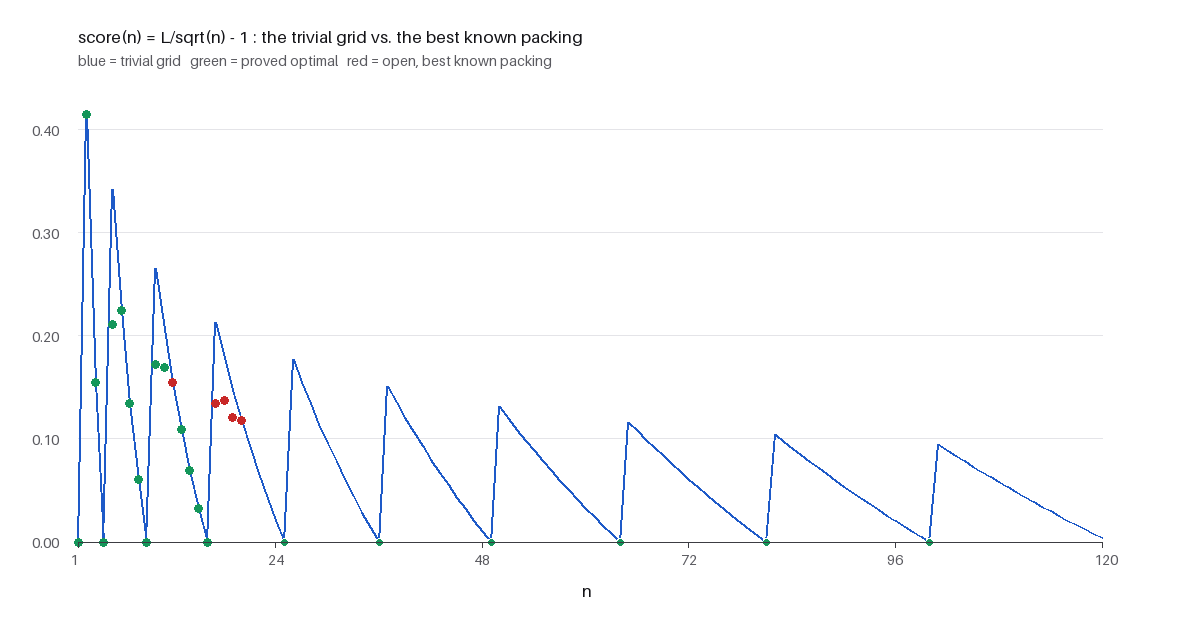

In [15]:
# --- figure: the sawtooth, with known optima overlaid -------------------
import os
from PIL import Image, ImageDraw, ImageFont

os.makedirs("figures", exist_ok=True)


def plot_sawtooth(path="figures/sawtooth.png", nmax=120):
    W, H, PAD = 1180, 620, 78
    img = Image.new("RGB", (W, H), "white")
    d = ImageDraw.Draw(img)
    try:
        f  = ImageFont.load_default(size=17)
        fs = ImageFont.load_default(size=14)
    except TypeError:                      # older Pillow
        f = fs = ImageFont.load_default()

    ns  = list(range(1, nmax + 1))
    ys  = [grid_side(n) / np.sqrt(n) - 1.0 for n in ns]
    ymax = 0.45

    def X(n):
        return PAD + (n - 1) / (nmax - 1) * (W - 2 * PAD)

    def Y(v):
        return H - PAD - v / ymax * (H - 2 * PAD)

    for v in [0.0, 0.1, 0.2, 0.3, 0.4]:
        d.line([(PAD, Y(v)), (W - PAD, Y(v))], fill=(228, 228, 232), width=1)
        d.text((PAD - 46, Y(v) - 8), f"{v:.2f}", font=fs, fill=(90, 90, 96))

    # the grid curve
    d.line([(X(n), Y(v)) for n, v in zip(ns, ys)], fill=(30, 90, 200), width=2)

    # perfect squares sit exactly on zero
    for k in range(1, int(nmax ** 0.5) + 1):
        n = k * k
        d.ellipse([X(n) - 4, Y(0) - 4, X(n) + 4, Y(0) + 4],
                  fill=(20, 150, 90), outline="white")

    # published best-known values for n <= 20
    for n, _, L, status, _, _ in KNOWN:
        if n <= nmax:
            v = score(L, n)
            c = (200, 40, 40) if status == "OPEN" else (20, 150, 90)
            d.ellipse([X(n) - 4, Y(v) - 4, X(n) + 4, Y(v) + 4], fill=c)

    d.line([(PAD, Y(0)), (W - PAD, Y(0))], fill=(60, 60, 66), width=1)
    for n in [1, 24, 48, 72, 96, 120]:
        d.line([(X(n), Y(0)), (X(n), Y(0) + 5)], fill=(60, 60, 66), width=1)
        d.text((X(n) - 8, Y(0) + 9), str(n), font=fs, fill=(90, 90, 96))
    d.text((PAD, 26), "score(n) = L/sqrt(n) - 1 : the trivial grid vs. the best known packing",
           font=f, fill=(20, 20, 24))
    d.text((PAD, 52), "blue = trivial grid   green = proved optimal   red = open, best known packing",
           font=fs, fill=(90, 90, 96))
    d.text((W // 2 - 8, Y(0) + 38), "n", font=f, fill=(20, 20, 24))
    img.save(path)
    return path


show_png(plot_sawtooth())

Read the picture like this: the **blue** curve is what the grid scores. It is
exactly $0$ at every green dot on the axis ($n=1,4,9,16,\ldots$) — those are the
31 puzzles with a known, unbeatable answer. Everywhere else the blue curve is
strictly above zero, with a sawtooth: it spikes just after each perfect square
and decays towards the next one.

The **red** dots are the best packings anyone has found for $n=17,18,19,20$.
The vertical distance from blue to red is the headroom on that puzzle; the fact
that the red dots are still *above* zero after fifty years of work is the open
problem.

## 7. A search engine, and an honest account of what it can do

The classic attack — and the one the core module implements — is **shrink-wrap**:

1. Start from a legal packing of side $L$.
2. Guess a smaller window $L' < L$ and squash the packing into it.
3. Repair the overlaps you just created with a physics-style relaxation: each
   overlapping pair is pushed apart along its minimum translation vector, and
   every square is clipped back into the window.
4. If the repair succeeds, the guess was feasible — keep $L'$ and repeat.
   If it fails, back off. This is bisection on $L$ with a feasibility oracle.

The rotational noise in `relax()` matters: without it the search can never
discover that a *tilted* square helps, which is exactly the move that separates
$2.707$ from $3$ for $n=5$.

What you should expect from it:

In [16]:
BEST_KNOWN = {          # from the table in section 4
    5: 2 + 0.5 ** 0.5,
    6: 3.0,
    7: 3.0,
    10: 3 + 0.5 ** 0.5,
    17: 4.67553009,
    18: 4.822875655,
}

print(f"{'n':>3} {'grid':>5} {'shrink L':>9} {'score':>8} "
      f"{'best kn.':>9} {'best sc.':>9} {'left':>7}   verdict")
print("-" * 76)
res = {}
for n in [5, 6, 7, 10, 17, 18]:
    r = shrink(n, rounds=45, iters=350, seed=7)
    res[n] = r
    g = grid_side(n)
    bk = BEST_KNOWN[n]
    left = score(r["L"], n) - score(bk, n)
    if left > 1e-9:
        verdict = "left on the table"
    elif abs(r["L"] - g) < 1e-9:
        verdict = "grid already optimal"
    else:
        verdict = "matched the record"
    print(f"{n:>3} {g:>5} {r['L']:>9.6f} {r['score']:>8.4f} "
          f"{bk:>9.6f} {score(bk, n):>9.4f} {left:>7.4f}   {verdict}")

  n  grid  shrink L    score  best kn.  best sc.    left   verdict
----------------------------------------------------------------------------
  5     3  2.784841   0.2454  2.707107    0.2107  0.0348   left on the table
  6     3  3.000000   0.2247  3.000000    0.2247  0.0000   grid already optimal
  7     3  3.000000   0.1339  3.000000    0.1339  0.0000   grid already optimal
 10     4  3.882097   0.2276  3.707107    0.1723  0.0553   left on the table
 17     5  5.000000   0.2127  4.675530    0.1340  0.0787   left on the table
 18     5  5.000000   0.1785  4.822876    0.1368  0.0417   left on the table


Look at the `verdict` column, because it separates two very different kinds of
"failure":

* **$n=6,7$ — nothing to gain.** The shrinker returns the grid unchanged because
  the grid *is* optimal there ($s=3$). A search that "fails" on these is
  correct; there is no lower place to go.
* **$n=5,10$ — partly solved.** Here the tilted optimum really is below the
  grid, and shrink-wrap captures most but not all of the gap ($2.785$ versus
  the optimal $2.707$). It never finds the *rigid* configuration where the
  tilted square and its four neighbours all touch at once.
* **$n=17,18$ — stuck.** It does not move at all, while published packings sit
  $0.08$ and $0.04$ score below it. These need the contact-graph search
  described next.

Three fixes, in order of return on effort:

1. **Seed from published packings.** The [Squares Project](https://squaremath.org)
   publishes coordinates for the best known packing of each $n$. Re-running a
   shrink-wrap from those coordinates is a cheap way to polish, and re-deriving
   the exact algebraic $L$ from a rigid contact graph beats any numeric search.
2. **Warm-start along $n$.** The best packing for $n$ is an excellent starting
   point for $n+1$ (add one square in a corner and let the shrinker redistribute).
3. **Basin hopping.** Keep the best configuration, shake it (random rotations,
   one square displaced), re-relax, keep if better. `shrink(..., kicks=...)`
   does a crude version of this. In trials, restarting from shaken
   configurations bought a few thousandths of $L$ for several times the run
   time — worth it only on puzzles you have already decided to care about.

In [17]:
# take the biggest win from the table above, add the safety gap, re-check
best_n = max(res, key=lambda n: score(grid_side(n), n) - res[n]["score"])
r = res[best_n]
xy_p, th_p = polish(r["xy"], r["th"], np.random.default_rng(0))
area, where = max_overlap_area(xy_p, th_p)
L_before, L_after = r["L"], container_side(xy_p, th_p)
print(f"n={best_n}: L before polish = {L_before:.9f}")
print(f"       L after  polish = {L_after:.9f}   (moved {L_after - L_before:+.1e})")
print(f"       SAT penetration  = {max_penetration(xy_p, th_p):.2e}  (negative = a gap)")
print(f"       overlap area     = {area:.1e}")
print(f"       is_valid         = {is_valid(xy_p, th_p)[0]}")
print()
print("polish() only pushes apart pairs closer than GAP=1e-7, so a packing that")
print("already has a positive gap is left exactly where it is. A sub-1e-7 gap")
print("would cost about 2e-7 of L to remove -- cheaper than risking a grader")
print("that counts 'touching' as 'overlapping'.")

n=5: L before polish = 2.784841268
       L after  polish = 2.784841268   (moved +0.0e+00)
       SAT penetration  = -1.43e-05  (negative = a gap)
       overlap area     = 0.0e+00
       is_valid         = True

polish() only pushes apart pairs closer than GAP=1e-7, so a packing that
already has a positive gap is left exactly where it is. A sub-1e-7 gap
would cost about 2e-7 of L to remove -- cheaper than risking a grader
that counts 'touching' as 'overlapping'.


## 8. Strategy for the competition

**1. Bank the 91 solved puzzles.** If $n=k^2$, $k^2-1$, or $k^2-2$, submit the
grid and move on: it is provably optimal, so 91 of the 1000 puzzles are banked
for free. The sporadic proofs are worth checking too: $n=6,13,21$ already sit
at the grid value, while $n=5,10,11$ need a non-grid packing (a tilted square
for 5 and 10, Trump's construction for 11) and are worth $0.131$, $0.093$ and
$0.037$ of score respectively — more than most people will extract from a
week of search on large $n$.

**2. Never lose to the grid.** The grader charges the grid ceiling for missing
or unparseable puzzles, so a *broken* packing is strictly worse than a plain
grid. Run `evaluate_submission()` on your own CSV before uploading: it re-reads
the file, rebuilds each packing, re-checks legality, and recomputes the exact
leaderboard sum. It also catches the classic own-goal — a `NaN`, or a row count
that does not match $n$.

**3. Spend effort where the headroom is.** From §6: puzzles just above a
perfect square, and small $n$ in general. Ranking candidates by
`grid score − best known score` gives you a work queue that is already
sorted for you.

**4. Exploit the derived container.** Because $L$ is derived, you cannot aim at
a target $L$: you must produce coordinates whose bounding box is that wide. Two
consequences worth exploiting:
* $L$ is **translation-invariant** — sliding a packing around costs nothing —
  but **scaling** is not. A stored packing that is $1.3\times$ too large costs
  $0.3L/\sqrt n$, which for $n=5$ is $0.36$ of score, nearly three times the
  entire gap to the optimum. Always rescale a recovered packing to unit-square
  side before submitting.
* if $w \ne h$ you are paying for the larger one, since $L=\max(w,h)$: balance
  them by rotating or anisotropically squashing.

**5. Submit in stages.** Partial submissions are scored with the grid ceiling
for everything missing, so an early submission of the 91 solved puzzles plus
the grids is a safe floor; then replace puzzles as you improve them. Never
regress: keep the best known configuration per $n$ in a JSON file and merge.

**6. Verify with two tests, always.** §5 shows why. Add a safety margin with
`polish()`; it costs $10^{-7}$ in $L$ and removes a whole class of
disqualifications.

## 9. Writing and self-scoring a submission

The format is one row per square:

```
id,n,square_id,x,y,angle
```

where `id` is a unique integer, `n` the puzzle, `square_id` runs
$0..n-1$, and `(x, y, angle)` are the centre and rotation. Coordinates must be
plain decimal literals — `repr()` of a Python float is exactly the shortest
round-tripping decimal, which is why the writer uses it.

The cell below writes a submission for the solved families (grid, provably
optimal) plus a few searched puzzles, then grades it with the same arithmetic
the leaderboard uses.

In [18]:
solutions = {}

# 1. the provably-optimal families: n = k^2, k^2-1, k^2-2  -> plain grid
for k in range(1, 32):
    for n in (k * k, k * k - 1, k * k - 2):
        if 1 <= n <= 1000:
            solutions[n] = grid(n)

# 2. the best searched packings from section 7 (polished for safety)
for n, r in res.items():
    xy_p, th_p = polish(r["xy"], r["th"], np.random.default_rng(0))
    if container_side(xy_p, th_p) < container_side(*solutions.get(n, grid(n))):
        solutions[n] = (xy_p, th_p)

write_submission("submission.csv", solutions)
print(f"wrote submission.csv with {len(solutions)} puzzles, "
      f"{sum(len(v[0]) for v in solutions.values())} squares")

report = evaluate_submission("submission.csv")
print(f"self-graded total (missing puzzles charged the grid): {report['total']:.6f}")
print(f"puzzles submitted: {len(solutions)}  |  grid-only total would be: {grid_total:.6f}")

wrote submission.csv with 93 puzzles, 31171 squares
self-graded total (missing puzzles charged the grid): 28.804164
puzzles submitted: 93  |  grid-only total would be: 28.937670


If your run reproduces the numbers above, the toolkit is working: the file is
valid, every submitted packing passes both overlap tests, and the total is
better than the all-grid baseline of $28.9377$ by exactly the headroom you
captured on the searched puzzles.

### Where to go next

* **Exact $L$ from a contact graph.** Once a packing is rigid, $L$ is determined
  by the contact equations; solving them symbolically gives you 15 correct
  digits and — more importantly — a certificate that the packing really is
  rigid. That is the difference between "a number my optimiser printed" and
  "this is optimal", and it is where the Lean scaffold in
  `lean/SquaresInSquares` would start: the §3 argument and the perfect-square
  cases are clean enough to state formally, and formalising *lower bounds* for
  specific $n$ is a genuinely open research programme.
* **Read the frontier.** [squaremath.org/frontier.html](https://squaremath.org/frontier.html)
  lists, for each $n$, the best known packing, the best lower bound, and a
  status — including who found it and when. That is your ground truth, and it
  is updated.

## 10. References

1. E. Friedman, *Packing Unit Squares in Squares: A Survey and New Results*,
   Electronic Journal of Combinatorics, Dynamic Survey DS7 (2009).
   [[link](https://erich-friedman.github.io/papers/squares/squares.html)]
2. *Square packing*, Wikipedia — carries the table of exact values for
   $n\le16$ and the attribution for each proof.
   [[link](https://en.wikipedia.org/wiki/Square_packing)]
3. The Squares Project, *Frontier Survey* — verified upper and lower bounds,
   per $n$, with status and provenance.
   [[link](https://squaremath.org/frontier.html)]
4. P. Erdős and R. L. Graham, *On packing squares with equal squares*,
   J. Combinatorial Theory A 19 (1975) 119–123.
5. K. F. Roth and R. C. Vaughan, *Inefficiency in packing squares with unit
   squares*, J. Combinatorial Theory A 24 (1978) 170–186.
6. F. Chung and R. Graham, *Packing equal squares into a large square*,
   J. Combinatorial Theory A 116 (2009) 1167–1175.
7. W. Stromquist, *Packing 10 or 11 unit squares in a square*,
   Electronic Journal of Combinatorics 10 (2003) R8.
8. W. Bentz, *Optimal packings of 13 and 46 unit squares in a square*,
   Electronic Journal of Combinatorics 17 (2010) R126.
9. H. Nagamochi, *Packing unit squares in a rectangle*,
   Electronic Journal of Combinatorics 12 (2005) R37.